In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/의료영상처리/DIP4E'

Mounted at /content/drive


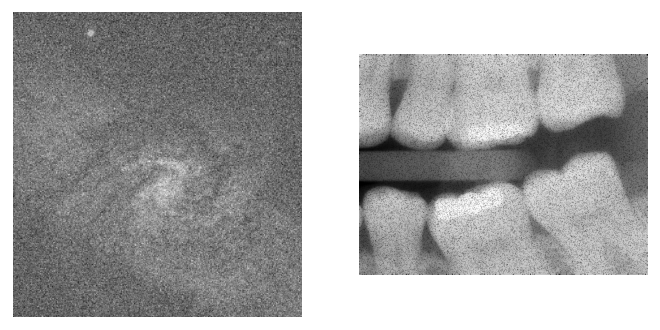

In [6]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2,cmap='gray')
plt.axis('off')
plt.show()

In [13]:
# Median Filtering

SS = 7
ss = int((SS-1)/2)
f2_r = np.zeros(np.shape(f2))

for x in range(ss,np.size(f2,0)-ss):
  for y in range(ss,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    f2_r[x,y] = np.median(Sxy)

In [12]:
# Adaptive Median Filtering

SS_vals = np.array([3, 5, 7])
f1_r = np.zeros(np.shape(f1))
r_median = np.zeros(np.shape(f1))
r_case = np.zeros(np.shape(f1))

ss_max = int((np.max(SS_vals)-1)/2)
for x in range(ss_max,np.size(f1,0)-ss_max):
  for y in range(ss_max,np.size(f1,1)-ss_max):
    flag_go = 1
    cnt = 0
    z_xy = f1[x,y]
    for SS in SS_vals:
      ss = int((SS-1)/2)
      Sxy = f1[x-ss:x-ss+SS,y-ss:y-ss+SS]
      z_med = np.median(Sxy)
      z_min = np.min(Sxy)
      z_max = np.max(Sxy)

      if cnt==0:
        r_median[x,y] = z_med

      if z_min<z_med and z_med<z_max:
        if z_min<z_xy and z_xy<z_max:
          f1_r[x,y] = z_xy
          flag_go = 0
        else:
          f1_r[x,y] = z_med
          flag_go = 0
      else:
        if SS == np.max(SS_vals):
          f1_r[x,y] = z_med
          flag_go = 0

      if flag_go==0:
        r_case[x,y] = cnt
        break
      cnt = cnt+1

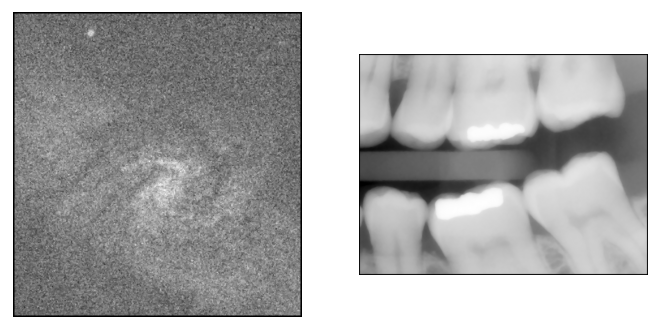

In [14]:
# f1_r: denoised f1
# f2_r: denoised f2
plt.figure(dpi=128)
plt.subplot(121)
plt.imshow(f1_r,cmap='gray')
plt.axis('off')
plt.subplot(122)
plt.imshow(f2_r,cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
plt.imsave('denoised-galaxy-pair.png',f1_r,cmap='gray')
plt.imsave('denoised-dentalXray.png',f2_r,cmap='gray')